# Notebook 1: Model 1, the base model (no training)

**Nutrition and Food Label Assistant, DS493 Phase 2.** This notebook gives the first row of `SCOREBOARD.md` ("Small model, base").

## Step 0. Settings you may change

In [1]:
RUN_MODE = "full"        # "full" = the real run used in the report; "smoke" = 5-question trial, saved separately
REQUIRE_GPU = True       # keep True: latency on the scoreboard must come from the T4

## Step 1. Check the runtime
Detects Colab / Kaggle, checks the GPU and the library versions. Nothing to edit.

In [2]:
import os, sys, json, time, hashlib, platform, importlib, importlib.util, subprocess, datetime, random, shutil

if importlib.util.find_spec("google.colab") is not None:
    ENV = "colab"
elif os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or os.path.exists("/kaggle/working"):
    ENV = "kaggle"
else:
    ENV = "local"
print("Environment:", ENV)

def need(pkg, pip_name=None):
    if importlib.util.find_spec(pkg) is None:
        print(f"Installing {pip_name or pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg], check=True)
for p in ["torch", "transformers", "yaml", "pandas", "requests", "safetensors"]:
    need(p, {"yaml": "pyyaml"}.get(p))

import torch, transformers, yaml, pandas as pd, requests
from packaging.version import Version
print("torch", torch.__version__, "| transformers", transformers.__version__, "| python", platform.python_version())
if Version(transformers.__version__) < Version("4.46"):
    raise RuntimeError(f"transformers {transformers.__version__} is too old (need 4.46 or newer). "
                       "Run:  !pip install -U transformers   then Runtime -> Restart session, and run again.")
transformers.logging.set_verbosity_error()      # hide long-text warnings (perplexity reads >1024 tokens in blocks)

if torch.cuda.is_available():
    DEVICE = "cuda"
    GPU = torch.cuda.get_device_name(0)
    print(f"GPU: {GPU}, memory {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    if "T4" not in GPU:
        print(f"NOTE: config expects a Tesla T4, this is {GPU}. Results are valid, but latency is not comparable "
              "with runs on a T4. Use the same GPU for all three notebooks.")
else:
    DEVICE, GPU = "cpu", "none"
    msg = ("No GPU found. In Colab: Runtime -> Change runtime type -> Hardware accelerator: T4 GPU -> Save, then "
           "Runtime -> Run all. In Kaggle: Settings (right panel) -> Accelerator -> GPU T4 x2.")
    if REQUIRE_GPU:
        raise RuntimeError(msg)
    print("WARNING:", msg, "Continuing on CPU because REQUIRE_GPU = False (latency will not be comparable).")

Environment: colab
torch 2.14.1+cu130 | transformers 5.22.1 | python 3.13.16
GPU: Tesla T4, memory 15.6 GB


## Step 2. Connect storage (Google Drive)
In Colab a pop-up asks you to allow access to your Google Drive: choose your account and press **Allow**.

In [3]:
# ---- Step 2. Download config.yaml from GitHub and connect storage ----
import os, importlib.util
import requests, yaml

CONFIG_URL = "https://raw.githubusercontent.com/Nutrition-Assistant-System/Nutrition-Assistant/main/Notebooks/config.yaml"

# Environment detection (same rules as Step 1; re-run only if Step 1 was skipped)
if "ENV" not in globals():
    if importlib.util.find_spec("google.colab") is not None:
        ENV = "colab"
    elif os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or os.path.exists("/kaggle/working"):
        ENV = "kaggle"
    else:
        ENV = "local"

# Download config.yaml
try:
    r = requests.get(CONFIG_URL, timeout=30)
except requests.RequestException as e:
    raise RuntimeError(f"Could not reach GitHub to download config.yaml:\n  {e}\n"
                       "Check the internet connection (Kaggle: Settings -> Internet -> On) and run this cell again.")
if r.status_code == 404:
    raise RuntimeError(f"config.yaml was not found at\n  {CONFIG_URL}\n"
                       "Check that the file is in the 'Notebooks' folder of the main branch (names are case-sensitive) "
                       "and that the repository is still public.")
if r.status_code != 200:
    raise RuntimeError(f"Downloading config.yaml failed with HTTP {r.status_code}. Wait a minute and run this cell again.")

# Parse it
try:
    cfg = yaml.safe_load(r.text)
except yaml.YAMLError as e:
    raise RuntimeError(f"config.yaml was downloaded but is not valid YAML:\n  {e}\n"
                       "Fix the indicated line in the repository (check indentation and quotes) and run this cell again.")
if not isinstance(cfg, dict) or "paths" not in cfg:
    raise RuntimeError("config.yaml was downloaded but has no 'paths' section. Check that the URL points to the project config.")
missing = [k for k in ("drive_root", "local_fallback_root") if not cfg["paths"].get(k)]
if missing:
    raise RuntimeError(f"config.yaml: paths.{', paths.'.join(missing)} is missing or empty.")
print(f"config.yaml loaded from GitHub (config_version {cfg.get('project', {}).get('config_version', '?')})")

# Storage root
if ENV == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = cfg["paths"]["drive_root"]
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError("Google Drive is not mounted. Run this cell again and press 'Allow' in the pop-up.")
elif ENV == "kaggle":
    ROOT = "/kaggle/working/nutrition-assistant"                # download it from the Output tab when finished
else:
    ROOT = os.path.abspath("nutrition-assistant")
os.makedirs(ROOT, exist_ok=True)
print("Environment:", ENV, "| all outputs go under:", ROOT)

config.yaml loaded from GitHub (config_version 2)
Mounted at /content/drive
Environment: colab | all outputs go under: /content/drive/MyDrive/nutrition-assistant


## Step 3. Secrets
`HF_TOKEN` is **optional** for GPT-2 (it is a public model). Add it if you have one: it avoids download rate limits. Tokens are never printed or saved.

In [11]:
def get_secret(name):
    if ENV == "colab":
        try:
            from google.colab import userdata
            return userdata.get(name)
        except Exception:
            pass
    if ENV == "kaggle":
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(name)
        except Exception:
            pass
    return os.environ.get(name)

HF_TOKEN = get_secret("HF_TOKEN")
print("HF_TOKEN:", "found (hidden)" if HF_TOKEN else "not set (fine for GPT-2)")

HF_TOKEN: not set (fine for GPT-2)


## Step 4. Shared code and configuration
These three files are identical in all three notebooks. Do not edit them here: edit `config.yaml` in the repository instead.

In [5]:
%%writefile prompting_tokens.py
import json, math, os
import torch


def build_prompt(question, cfg):
    """The ONE prompt format used for Base, CPT and SFT, in training and in evaluation."""
    return cfg["prompting"]["template"].format(question=question.strip())


def build_target(answer, cfg):
    """SFT target: a leading space, the answer, then the end marker directly (no space before it,
    which would add an extra "Ġ" token the model must learn to emit before stopping)."""
    return cfg["prompting"]["target"].format(answer=answer.strip())


def _markers(cfg):
    st = cfg["prompting"]["special_tokens"]
    return [st["user"], st["assistant"], st["end"]]


def stop_token_ids(tok, cfg):
    """Generation stops at <|end|> (learned in SFT) or at the tokenizer's EOS (<|endoftext|>)."""
    return sorted({tok.convert_tokens_to_ids(cfg["prompting"]["special_tokens"]["end"]), tok.eos_token_id})


def prepare_project_tokenizer(tok, model, cfg):
    """Base notebook ONLY: add the 3 special tokens, set padding, resize the embeddings, record the IDs."""
    if any(t in tok.get_vocab() for t in _markers(cfg)):
        raise RuntimeError("special tokens already present: load later stages with load_project_checkpoint")
    tok.add_special_tokens({"additional_special_tokens": _markers(cfg)})
    if tok.pad_token is None:                      # GPT-2 has no pad token: pad with EOS (always masked)
        tok.pad_token = tok.eos_token
    model.resize_token_embeddings(len(tok))        # new rows sampled around the mean of existing rows
    return _finish(tok, model, cfg)


def _finish(tok, model, cfg):
    model.generation_config.eos_token_id = stop_token_ids(tok, cfg)
    model.generation_config.pad_token_id = tok.pad_token_id
    return {"special_token_ids": {t: tok.convert_tokens_to_ids(t) for t in _markers(cfg)},
            "vocab_size": len(tok), "base_vocab_size": cfg["prompting"]["project_tokenizer"]["base_vocab_size"],
            "eos_token_id": tok.eos_token_id, "pad_token_id": tok.pad_token_id,
            "stop_token_ids": stop_token_ids(tok, cfg)}


def check_project_tokenizer(tok, model, cfg):
    """Fail loudly if a tokenizer/model pair is not the project tokenizer from config.yaml."""
    exp = cfg["prompting"]["project_tokenizer"]
    problems = []
    for t, i in exp["special_token_ids"].items():
        enc = tok.encode(t, add_special_tokens=False)
        if enc != [i]:
            problems.append(f"{t} encodes to {enc}, expected [{i}]")
    if len(tok) != exp["vocab_size"]:
        problems.append(f"tokenizer size {len(tok)}, expected {exp['vocab_size']}")
    if model.get_input_embeddings().weight.shape[0] != len(tok):
        problems.append(f"embedding rows {model.get_input_embeddings().weight.shape[0]} != tokenizer size {len(tok)}")
    if tok.pad_token_id is None:
        problems.append("no pad token")
    if exp.get("tied_lm_head") and model.lm_head.weight.data_ptr() != model.get_input_embeddings().weight.data_ptr():
        problems.append("input and output embeddings are no longer tied")
    if problems:
        raise RuntimeError("Project tokenizer check failed:\n  - " + "\n  - ".join(problems))
    return True


def load_project_checkpoint(path, cfg, device=None):
    """CPT, SFT and scoring: load a saved checkpoint and its tokenizer; check; never add tokens."""
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(path)
    check_project_tokenizer(tok, model, cfg)
    _finish(tok, model, cfg)
    if device:
        model.to(device)
    return tok, model.eval()


def cpt_collate(blocks):
    """CPT batches: every block is exactly block_size tokens, so there is no padding and every token,
    including the <|endoftext|> between documents, is a training label. (DataCollatorForLanguageModeling
    must NOT be used: with pad = EOS it would turn every document-boundary EOS label into -100.)"""
    ids = torch.tensor([b["input_ids"] for b in blocks])
    return {"input_ids": ids, "attention_mask": torch.ones_like(ids), "labels": ids.clone()}


def sft_collate(batch, pad_id):
    """SFT batches: right-pad input_ids with pad_id (attention 0) and labels with -100 (no loss)."""
    m = max(len(x["input_ids"]) for x in batch)
    pad = lambda x, v: x + [v] * (m - len(x))
    return {"input_ids": torch.tensor([pad(x["input_ids"], pad_id) for x in batch]),
            "attention_mask": torch.tensor([pad([1] * len(x["input_ids"]), 0) for x in batch]),
            "labels": torch.tensor([pad(x["labels"], -100) for x in batch])}


def encode_sft_example(tok, question, answer, cfg, max_length):
    """Prompt and target are tokenized separately (as at inference, where only the prompt is given),
    then joined. Labels are -100 on prompt tokens: the loss is on the answer and <|end|> only."""
    p_ids = tok(build_prompt(question, cfg), add_special_tokens=False)["input_ids"]
    a_ids = tok(build_target(answer, cfg), add_special_tokens=False)["input_ids"]
    if len(p_ids) + len(a_ids) > max_length:
        raise ValueError(f"example longer than max_length={max_length}: the <|end|> marker would be cut off")
    return {"input_ids": p_ids + a_ids, "labels": [-100] * len(p_ids) + a_ids}


@torch.no_grad()
def heldout_perplexity(tok, model, text, cfg, block_size=512):
    """Held-out perplexity over the ORIGINAL vocabulary: logits are cut to the first base_vocab_size
    entries before the softmax. The held-out text never contains the 3 new tokens, so this equals the
    perplexity of the unmodified model and is comparable across Base, CPT and SFT."""
    V = cfg["prompting"]["project_tokenizer"]["base_vocab_size"]
    ids = tok(text, add_special_tokens=False)["input_ids"]
    if any(i >= V for i in ids):
        raise ValueError("held-out text contains project special tokens")
    ids = torch.tensor(ids)
    was_training = model.training
    model.eval()                                   # dropout off: perplexity must be deterministic
    nll, count = 0.0, 0
    for i in range(0, len(ids) - 1, block_size):
        chunk = ids[i:i + block_size].unsqueeze(0).to(model.device)
        if chunk.shape[1] < 2:
            continue
        logits = model(chunk).logits[0, :-1, :V].float()
        nll += torch.nn.functional.cross_entropy(logits, chunk[0, 1:], reduction="sum").item()
        count += chunk.shape[1] - 1
    model.train(was_training)
    return math.exp(nll / count)


def clean_answer(text, cfg):
    """Cut a decoded answer at the first stop string (end marker, a new turn, or EOS text)."""
    for s in cfg["prompting"]["stop_strings"]:
        i = text.find(s)
        if i != -1:
            text = text[:i]
    return text.strip()


@torch.no_grad()
def generate_answer(tok, model, question, cfg):
    """The ONE function every stage and score.py uses to query a model (greedy, same length)."""
    g = cfg["generation"]
    stops = stop_token_ids(tok, cfg)
    enc = tok(build_prompt(question, cfg), return_tensors="pt", add_special_tokens=False).to(model.device)
    out = model.generate(**enc, max_new_tokens=g["max_new_tokens"], do_sample=False, num_beams=1,
                         repetition_penalty=g.get("repetition_penalty", 1.0),
                         eos_token_id=stops, pad_token_id=tok.pad_token_id)
    new = out[0][enc["input_ids"].shape[1]:]
    stopped = bool(len(new)) and int(new[-1]) in stops
    text = tok.decode(new, skip_special_tokens=False)
    return clean_answer(text, cfg), {"new_tokens": int(len(new)), "stopped_at_stop_token": stopped}


def save_with_tokenizer(model, tok, out_dir, cfg):
    """Save model + tokenizer + recorded token IDs together. Use for EVERY saved checkpoint (each CPT
    pass, best CPT, best SFT) so any folder can be loaded with load_project_checkpoint."""
    os.makedirs(out_dir, exist_ok=True)
    model.save_pretrained(out_dir)
    tok.save_pretrained(out_dir)
    json.dump(_finish(tok, model, cfg), open(os.path.join(out_dir, "project_tokens.json"), "w"), indent=2)

Writing prompting_tokens.py


In [6]:
%%writefile scoring.py

import hashlib, json, re
import pandas as pd


def test_fingerprint(df):
    """sha256 of the compact JSON list of [id, question, expected_answer] (config.yaml: test_set.fingerprint)."""
    rows = [[str(r.id), str(r.question), str(r.expected_answer)] for r in df.itertuples()]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(",", ":")).encode("utf-8")).hexdigest()


def normalise(text):
    t = str(text).lower()
    t = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", t)     # thousands separator: 1,139 -> 1139
    return re.sub(r"\s+", " ", t).strip()


def numbers(text):
    return set(re.findall(r"\d+(?:\.\d+)?", normalise(text)))


def declined(answer, cfg):
    pats = cfg["evaluation"]["should_decline"]["patterns"]
    return any(re.search(p, str(answer), re.I) for p in pats)


def auto_score(row, answer, cfg):
    """Returns (score or None, reason, score_source). None = needs hand grading (pending)."""
    if row["scoring"] == "decline":
        d = declined(answer, cfg)
        return (1.0 if d else 0.0), ("declined" if d else "answered instead of declining"), "auto"
    if row["scoring"] == "key_match":
        if declined(answer, cfg):
            return float(cfg["evaluation"]["short_answers"]["declined_answer_scores"]), "declined a question it should answer", "auto"
        keys = [k.strip() for k in str(row["key_answer"]).split("|") if k.strip()]
        hit = any(numbers(k) and numbers(k) <= numbers(answer) for k in keys)
        return (1.0 if hit else 0.0), ("key value found" if hit else "key value missing"), "auto"
    return None, "pending: needs two hand grades", "human"


def summarise(results):
    """Metrics for one model. `results` has columns scoring, should_decline, auto_score, final_score, latency_s."""
    auto = results[results.scoring != "manual"]
    dec = results[results.should_decline == "yes"]
    pending = int(results.final_score.isna().sum())
    return {
        "n_questions": int(len(results)),
        "n_pending_manual": pending,
        "accuracy": None if pending else round(100 * results.final_score.astype(float).mean(), 1),
        "accuracy_provisional_auto_only": round(100 * auto.auto_score.astype(float).mean(), 1) if len(auto) else None,
        "n_auto_scored": int(len(auto)),
        "refusal_accuracy": round(100 * dec.auto_score.astype(float).mean(), 1) if len(dec) else None,
        "mean_latency_s": round(float(results.latency_s.mean()), 3),
        "by_difficulty_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                               for k, g in auto.groupby("difficulty")},
        "by_scoring_type_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                                 for k, g in auto.groupby("scoring")},
    }

Writing scoring.py


In [7]:
%%writefile config_embedded.yaml

project:
  name: nutrition-food-label-assistant
  course_phase: 2
  config_version: 2                      # bump when a change here can affect results; saved with every run
  brief: "Team Project - Phase 2: Train a Small Model and Evaluate It"


run:

  pipeline_model: gpt2-small
  baseline_references: []                # e.g. [smollm2-135m, qwen2.5-0.5b, smollm2-135m-instruct]
  seed: 42                               # fixed seed for data splits, training and evaluation
  run_name: null                         # null -> automatic "<stage>_<model_key>_<YYYYmmdd-HHMM>"
  smoke_test:                            # brief tip: test small first (about 10 min on 5% of the data)
    enabled: false                       # true = quick trial run; its results are NOT used in the report
    data_fraction: 0.05
    max_minutes: 10
    test_questions: 5                    # first 5 questions only, for checking score.py


credentials:
  source_order: [colab_secrets, environment, prompt]   # prompt = hidden getpass() input, never saved
  secrets:
    huggingface: HF_TOKEN                # only for gated models or a private Hub repo for checkpoints
    github: GITHUB_TOKEN                 # optional: only if the data repository is made private again

runtime:
  device: auto                           # cuda if available, else cpu
  expected_gpu: Tesla T4
  inference_dtype_default: float32       # small models: float32 is exact and fits easily
  training_precision: fp16_mixed         # fp32 weights + fp16 autocast (Trainer fp16=True); no bf16 on T4
  hf_cache_dir: null                     # null = default; set a Drive path to avoid re-downloading weights


models:
  gpt2-small:                            # recommended by the brief
    model_id: openai-community/gpt2
    revision: main
    role: pipeline_candidate
    params_m: 124
    family: base
    prompt_style: project_template
    gated: false
    dtype: float32
    max_context: 1024
    tokenizer_notes: "no pad token (use EOS); no chat template; notebook 1 adds <|user|> <|assistant|> <|end|> once (ids 50257-50259)"
    train: {cpt_batch_size: 8, sft_batch_size: 8, grad_accum: 1, gradient_checkpointing: false}
  smollm2-135m:                          # allowed by the brief as the alternative
    model_id: HuggingFaceTB/SmolLM2-135M
    revision: main
    role: pipeline_candidate
    params_m: 135
    family: base
    prompt_style: project_template
    gated: false
    dtype: float32
    max_context: 8192                    # CPT still uses 512-token blocks (brief)
    tokenizer_notes: "49k vocabulary; set pad = EOS if missing; add the same 3 special tokens at SFT"
    train: {cpt_batch_size: 8, sft_batch_size: 8, grad_accum: 1, gradient_checkpointing: false}
  smollm2-360m:                          # same family, bigger: comparison only (brief limits the pipeline)
    model_id: HuggingFaceTB/SmolLM2-360M
    revision: main
    role: baseline_reference
    params_m: 362
    family: base
    prompt_style: project_template
    gated: false
    dtype: float32
    max_context: 8192
    tokenizer_notes: "same tokenizer as smollm2-135m"
  qwen2.5-0.5b:                          # different family, base model: comparison only
    model_id: Qwen/Qwen2.5-0.5B
    revision: main
    role: baseline_reference
    params_m: 494
    family: base
    prompt_style: project_template
    gated: false
    dtype: float16
    max_context: 32768
    tokenizer_notes: "151k vocabulary; different tokenizer from GPT-2"
  smollm2-135m-instruct:                 # already instruction-tuned: shows what tuning at scale adds
    model_id: HuggingFaceTB/SmolLM2-135M-Instruct
    revision: main
    role: baseline_reference
    params_m: 135
    family: instruct
    prompt_style: native_chat
    gated: false
    dtype: float32
    max_context: 8192
    tokenizer_notes: "uses its own chat template; not comparable as a 'base' model"
  qwen2.5-0.5b-instruct:
    model_id: Qwen/Qwen2.5-0.5B-Instruct
    revision: main
    role: baseline_reference
    params_m: 494
    family: instruct
    prompt_style: native_chat
    gated: false
    dtype: float16
    max_context: 32768
    tokenizer_notes: "uses its own chat template"
  llama-3.2-1b-instruct:                 # gated; inference only on the T4
    model_id: meta-llama/Llama-3.2-1B-Instruct
    revision: main
    role: baseline_reference
    params_m: 1236
    family: instruct
    prompt_style: native_chat
    gated: true
    dtype: float16
    max_context: 131072
    tokenizer_notes: "uses its own chat template; needs HF_TOKEN and accepted licence"


prompting:
  template: "<|user|> {question}\n<|assistant|>"
  target: " {answer}<|end|>"             # SFT target; NO space before <|end|> (a space adds an extra "Ġ" token)
  special_tokens: {user: "<|user|>", assistant: "<|assistant|>", end: "<|end|>"}
  add_special_tokens_at: project_tokenizer   # added ONCE, before Model 1 is scored; never again
  project_tokenizer:                     # what every checkpoint must carry (checked on every load)
    base_vocab_size: 50257               # GPT-2: <|endoftext|> = 50256 is eos, bos and unk; no pad token
    vocab_size: 50260
    special_token_ids: {"<|user|>": 50257, "<|assistant|>": 50258, "<|end|>": 50259}
    pad_token: "<|endoftext|>"           # padding is masked (attention 0, label -100), so EOS is safe
    new_embedding_init: mean             # transformers default (mean + covariance of existing rows)
    tied_lm_head: true                   # GPT-2 ties input and output embeddings; resize keeps the tie
    saved_with_every_checkpoint: project_tokens.json
  stop_token_ids_from: ["<|end|>", "<|endoftext|>"]  # generation_config.eos_token_id = [50256, 50259]
  stop_strings: ["<|end|>", "<|user|>", "<|assistant|>", "<|endoftext|>"]  # text cut after decoding
  tokenize_with_add_special_tokens: false    # nothing is prepended or appended by the tokenizer
  system_prompt: null                    # none: identical input for every model


generation:
  do_sample: false                       # greedy = temperature 0
  max_new_tokens: 96                     # same maximum answer length for every model
  repetition_penalty: 1.0                # no penalty: keeps "does not stop / repeats itself" visible
  batch_size: 1                          # one question at a time: clean per-question latency
  latency: wall_clock_seconds_per_answer # reported as "Avg. latency (s)" on the scoreboard


test_set:
  repo_path: tests/test_questions.csv
  n_questions: 30
  fingerprint:                           # sha256 of the JSON list of [id, question, expected_answer]
    method: sha256_json_id_question_expected      # compact JSON (separators "," ":"), UTF-8, ids as text
    value: 0ab302fef36a194853886f6b82e0177d3881a4c4ad122fc9c5d2a343fba769de
  columns: [id, question, expected_answer, source, difficulty, key_answer, should_decline, scoring]
  difficulty_mix: {easy: 15, medium: 10, hard: 2, refusal: 3}
  scoring_mix: {key_match: 18, decline: 4, manual: 8}
  change_policy: "fix clear mistakes only, note each change in the decision log, re-score every model"


evaluation:
  short_answers:                         # 18 questions with a short exact answer (a number, yes/no)
    method: exact_match_on_key_value     # see note (needs team approval): normalise, then the key value
    normalize: [lowercase, collapse_spaces, remove_thousands_separator]   # must appear in the answer
    accept_alternatives: true            # key_answer "49.93|49.9" -> either counts
    declined_answer_scores: 0
  should_decline:                        # 4 questions: 3 out of scope + 1 unanswerable (brief definition)
    correct_if_declines: true
    patterns:
      - "i don'?t have (that|this|the) information"
      - "i can'?t help|i cannot help|i'?m not able to"
      - "not in my (nutrition )?data|outside what i do|out of scope"
      - "ask a (doctor|registered dietitian)|consult|i don'?t know"
  manual:                                # 8 longer answers: graded by hand
    graders: 2                           # two team members, independently
    scale: {correct: 1.0, partly_correct: 0.5, wrong: 0.0}
    checklist: [factual_accuracy, numerical_accuracy, answer_relevance, groundedness, refusal_accuracy,
                units_and_serving_sizes]  # Phase 1 criteria, used by graders as a checklist
    pending_until: both_graders_done     # a pending grade is NEVER counted as 0 or as wrong
    agreement: exact_match_of_the_two_scores   # "how often the graders agreed at first"
    resolution: discuss_then_final_score
  score_sources: [auto, human]           # every row records which one produced its final score
  metrics:
    accuracy: "mean final score over all 30; reported only when no grade is pending"
    accuracy_provisional: "auto-scored questions only (22), clearly labelled; never mixed with final"
    refusal_accuracy: "declined / should-decline questions (4)"
    breakdowns: [by_difficulty, by_scoring_type]
    mean_latency_s: true
    heldout_perplexity: "notebook 1: base model (before); notebook 2: base again + CPT model (after); notebook 3: SFT model"
    perplexity_vocab: original           # softmax over the first 50,257 logits only, so adding the 3 tokens
                                         # cannot change it; same blocks, same text, dropout off, for every model
  error_analysis:                        # required for the SFT model: every wrong answer gets one cause
    applies_to: sft
    categories: [format_failure, hallucination, knowledge_missing, refusal_error, test_case_problem]


paths:
  drive_root: /content/drive/MyDrive/nutrition-assistant
  local_fallback_root: /content/nutrition-assistant     # if Drive is not mounted (lost at session end)
  results_dir: "{root}/results/{stage}/{model_key}/{run_name}"
  checkpoints_dir: "{root}/checkpoints/{model_key}"     # cpt/epoch-N, cpt/best, sft/epoch-N, sft/best
  repo_exports_dir: "{root}/repo_exports"               # files to commit: scripts, results, SCOREBOARD.md
  hf_hub_repo: null                      # optional private Hub repo for checkpoints, e.g. team/nutrition-gpt2

scoreboard:
  file: SCOREBOARD.md
  columns: [Version, Held-out perplexity, Accuracy, Refusal accuracy, Avg. latency (s), Notes]
  required_rows: ["Small model, base", "+ continued pretraining", "+ SFT"]
  reference_rows_label: "Reference (base only, not trained)"


data_sources:
  base_url: https://raw.githubusercontent.com/Nutrition-Assistant-System/Nutrition-Assistant/main
  private_repo: false                    # public since 12 Nov 2026; GITHUB_TOKEN no longer needed
  merged_items: Data/foods_and_products.csv
  cpt_train: Data/CPT/train.txt          # 889 documents (90%)
  cpt_heldout: Data/CPT/heldout.txt      # 99 documents (10%), split by document
  sft_pairs: Data/SFT/sft_pairs.jsonl    # 894 pairs; none from test items
  test_questions: Data/test_questions.csv

stages:
  base: {}                               # Model 1: no training
  cpt:                                   # Model 2: brief Part A, Step 1
    start_from: base_project             # base checkpoint saved by notebook 1 (with the 3 tokens added)
    block_size: 512                      # sequences of 512 tokens
    collator: cpt_collate                # no padding; keeps EOS labels (NOT DataCollatorForLanguageModeling)
    epochs: 3                            # 1-3 passes
    learning_rate: 5.0e-5                # around 5e-5
    warmup_ratio: 0.05
    weight_decay: 0.01
    save_every_epoch: true               # a checkpoint after each pass
    early_stopping_patience: 1           # stop when validation loss stops falling
    keep_best_by: eval_loss
    eval_prompts:                        # the same 5 prompts, completed before and after
      - "Chicken breast, cooked, roasted. Per 100 g:"
      - "Lentils, mature seeds, cooked, boiled. Per 100 g it contains"
      - "Ingredients: whole grain oats, sugar,"
      - "Breakfast cereal. Serving size: 30 g. Per 100 g:"
      - "Greek yogurt, plain, nonfat. Per 100 g:"
  sft:                                   # Model 3: brief Part A, Step 2
    start_from: cpt_best                 # best CPT checkpoint of the SAME model
    method: full_fine_tuning             # full fine-tuning is fine at this size (LoRA optional)
    max_length: 384
    epochs: 3                            # 2-3 passes
    learning_rate: 5.0e-5
    warmup_ratio: 0.05
    weight_decay: 0.01
    val_fraction: 0.10                   # keep 10% of the pairs for validation
    early_stopping_patience: 1
    loss_on_answers_only: true           # prompt tokens get label -100
    add_special_tokens: false            # already in the project tokenizer (prompting)
    on_too_long: error                   # never truncate; longest pair is 94 tokens

Writing config_embedded.yaml


In [8]:
import importlib, prompting_tokens as pt, scoring as sc
importlib.reload(pt); importlib.reload(sc)
sha = lambda path: hashlib.sha256(open(path, "rb").read()).hexdigest()

REPO_RAW = "https://raw.githubusercontent.com/Nutrition-Assistant-System/Nutrition-Assistant/main"
embedded = yaml.safe_load(open("config_embedded.yaml"))
cfg, CONFIG_SOURCE = embedded, "embedded copy in this notebook"
try:                                             # if config.yaml is in the repository, it is the source of truth
    r = requests.get(f"{REPO_RAW}/config.yaml", timeout=30)
    if r.status_code == 200:
        repo_cfg = yaml.safe_load(r.text)
        if repo_cfg != embedded:
            print("NOTE: config.yaml in the repository differs from the copy in this notebook -> using the repository version.")
        cfg, CONFIG_SOURCE = repo_cfg, "repository config.yaml"
except requests.RequestException:
    pass
print("Config:", CONFIG_SOURCE, "| version", cfg["project"]["config_version"])

# ---- sanity checks on the settings this notebook depends on ----
MODEL_KEY = cfg["run"]["pipeline_model"]
M = cfg["models"][MODEL_KEY]
problems = []
if M["role"] != "pipeline_candidate":
    problems.append(f"run.pipeline_model = {MODEL_KEY} is not a pipeline_candidate")
if cfg["run"]["baseline_references"]:
    problems.append("run.baseline_references is not empty: reference models are not part of this notebook version")
if cfg["generation"]["do_sample"] is not False:
    problems.append("generation.do_sample must be false (greedy decoding, brief)")
if cfg["prompting"]["add_special_tokens_at"] != "project_tokenizer":
    problems.append("prompting.add_special_tokens_at must be project_tokenizer")
if ENV == "colab" and cfg["paths"]["drive_root"] != ROOT:
    problems.append(f"paths.drive_root is {cfg['paths']['drive_root']}, but this notebook uses {ROOT}")
if problems:
    raise RuntimeError("config.yaml problem(s):\n - " + "\n - ".join(problems))

SEED = cfg["run"]["seed"]
random.seed(SEED); torch.manual_seed(SEED)
SMOKE = RUN_MODE == "smoke"
STAMP = datetime.datetime.now().strftime("%Y%m%d-%H%M")
RUN_NAME = cfg["run"]["run_name"] or f"{'smoke_' if SMOKE else ''}base_{MODEL_KEY}_{STAMP}"
RESULTS = cfg["paths"]["results_dir"].format(root=ROOT, stage="base", model_key=MODEL_KEY, run_name=RUN_NAME)
CKPT = cfg["paths"]["checkpoints_dir"].format(root=ROOT, model_key=MODEL_KEY) + ("/base_project_smoke" if SMOKE else "/base_project")
EXPORTS = cfg["paths"]["repo_exports_dir"].format(root=ROOT)
for d in [RESULTS, EXPORTS + "/results"]:
    os.makedirs(d, exist_ok=True)
print(f"Model: {MODEL_KEY} ({M['model_id']}) | mode: {RUN_MODE}\nResults:    {RESULTS}\nCheckpoint: {CKPT}")

Config: embedded copy in this notebook | version 2
Model: gpt2-small (openai-community/gpt2) | mode: full
Results:    /content/drive/MyDrive/nutrition-assistant/results/base/gpt2-small/base_gpt2-small_20261113-1307
Checkpoint: /content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/base_project


## Step 5. Download the data and check the test set

In [9]:
DATA = os.path.join(ROOT, "data_cache"); os.makedirs(DATA, exist_ok=True)
GH_TOKEN = get_secret(cfg["credentials"]["secrets"]["github"]) if cfg["data_sources"]["private_repo"] else None

def download(key):
    rel = cfg["data_sources"][key]
    url = f"{cfg['data_sources']['base_url']}/{rel}"
    headers = {"Authorization": f"token {GH_TOKEN}"} if GH_TOKEN else {}
    try:
        r = requests.get(url, headers=headers, timeout=60)
    except requests.RequestException as e:
        raise RuntimeError(f"Could not reach GitHub for {rel}: {e}. Check the internet connection and run this cell again.")
    if r.status_code == 404:
        raise RuntimeError(f"{rel} was not found (404). Check that the file exists at this path in the repository "
                           "(names are case-sensitive: Data/CPT/..., Data/SFT/...). If the repository was made private, "
                           "set data_sources.private_repo: true and add the GITHUB_TOKEN secret.")
    r.raise_for_status()
    path = os.path.join(DATA, os.path.basename(rel))
    open(path, "wb").write(r.content)
    print(f"  {rel}: {len(r.content):,} bytes")
    return path

files = {k: download(k) for k in ["cpt_heldout", "test_questions"]}
heldout_text = open(files["cpt_heldout"], encoding="utf-8").read()
tests = pd.read_csv(files["test_questions"], dtype=str).fillna("")

T = cfg["test_set"]
missing_cols = [c for c in T["columns"] if c not in tests.columns]
if missing_cols:
    raise RuntimeError(f"test_questions.csv is missing columns {missing_cols}")
if len(tests) != T["n_questions"]:
    raise RuntimeError(f"test_questions.csv has {len(tests)} rows, expected {T['n_questions']}")
fp = sc.test_fingerprint(tests)
if fp != T["fingerprint"]["value"]:
    raise RuntimeError("The test set has changed (fingerprint mismatch). Every model must be scored on the same frozen "
                       "test set. If the change was intended, follow test_set.change_policy and update the fingerprint "
                       f"in config.yaml.\n  expected {T['fingerprint']['value']}\n  got      {fp}")
mix = tests.scoring.value_counts().to_dict()
if mix != T["scoring_mix"]:
    raise RuntimeError(f"Scoring mix {mix} differs from config {T['scoring_mix']}")
heldout_docs = [d for d in heldout_text.split("\n\n") if d.strip()]
print(f"Test set OK: {len(tests)} questions, fingerprint matches, mix {mix}")
print(f"Held-out text: {len(heldout_docs)} documents, {len(heldout_text):,} characters")
if SMOKE:
    tests = tests.head(cfg["run"]["smoke_test"]["test_questions"]).copy()
    heldout_text = "\n\n".join(heldout_docs[:max(1, int(len(heldout_docs) * cfg["run"]["smoke_test"]["data_fraction"]))])
    print(f"SMOKE MODE: {len(tests)} questions and {len(heldout_text):,} characters of held-out text")

  Data/CPT/heldout.txt: 56,194 bytes
  Data/test_questions.csv: 8,332 bytes
Test set OK: 30 questions, fingerprint matches, mix {'key_match': 18, 'manual': 8, 'decline': 4}
Held-out text: 99 documents, 56,183 characters


## Step 6. Load pretrained GPT-2 Small and measure its perplexity
*Perplexity* = how surprised the model is by unseen text (lower is better). It is measured on the 99 held-out documents in 512-token blocks.

In [12]:
from transformers import AutoTokenizer, AutoModelForCausalLM
t0 = time.time()
try:
    tok = AutoTokenizer.from_pretrained(M["model_id"], revision=M["revision"], token=HF_TOKEN)
    model = AutoModelForCausalLM.from_pretrained(M["model_id"], revision=M["revision"], token=HF_TOKEN)
except OSError as e:
    raise RuntimeError(f"Could not download {M['model_id']} from Hugging Face: {e}\n"
                       "Check the internet connection; if you see 'rate limit' or 429, add the HF_TOKEN secret.")
model.to(DEVICE).eval()
MODEL_COMMIT = getattr(model.config, "_commit_hash", None)
PT = cfg["prompting"]["project_tokenizer"]
checks = {
    "vocabulary size 50,257": len(tok) == PT["base_vocab_size"],
    "<|endoftext|> is id 50256 (EOS)": tok.eos_token_id == 50256,
    "chat tokens not yet in the vocabulary": not any(t in tok.get_vocab() for t in cfg["prompting"]["special_tokens"].values()),
    "input/output embeddings tied": model.lm_head.weight.data_ptr() == model.get_input_embeddings().weight.data_ptr(),
    "weights in float32": model.dtype == torch.float32,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
if not all(checks.values()):
    raise RuntimeError("The downloaded model is not the expected GPT-2 Small (see FAIL lines above).")
print(f"Loaded {M['model_id']} (commit {MODEL_COMMIT}) on {DEVICE} in {time.time() - t0:.0f}s, "
      f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters")

ppl_plain = pt.heldout_perplexity(tok, model, heldout_text, cfg, block_size=cfg["stages"]["cpt"]["block_size"])
print(f"Held-out perplexity, plain GPT-2: {ppl_plain:.3f}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

PASS vocabulary size 50,257
PASS <|endoftext|> is id 50256 (EOS)
PASS chat tokens not yet in the vocabulary
PASS input/output embeddings tied
PASS weights in float32
Loaded openai-community/gpt2 (commit None) on cuda in 19s, 124M parameters
Held-out perplexity, plain GPT-2: 12.294


## Step 7. Add the three chat tokens (once) and re-check
After this step GPT-2 has 50,260 tokens. The new tokens are not used by the held-out text, so perplexity must stay the same.

In [13]:
info = pt.prepare_project_tokenizer(tok, model, cfg)
model.to(DEVICE).eval()
pt.check_project_tokenizer(tok, model, cfg)
expected_ids = PT["special_token_ids"]
ids_ok = info["special_token_ids"] == expected_ids and info["vocab_size"] == PT["vocab_size"]
print(("PASS " if ids_ok else "FAIL ") + f"token ids {info['special_token_ids']}, vocabulary {info['vocab_size']}")
if not ids_ok:
    raise RuntimeError(f"Special-token ids differ from config.yaml ({expected_ids}).")

ppl_project = pt.heldout_perplexity(tok, model, heldout_text, cfg, block_size=cfg["stages"]["cpt"]["block_size"])
rel = abs(ppl_project - ppl_plain) / ppl_plain
print(("PASS " if rel < 1e-4 else "FAIL ") + f"perplexity unchanged: {ppl_plain:.3f} -> {ppl_project:.3f} (relative difference {rel:.1e})")
if rel >= 1e-4:
    raise RuntimeError("Perplexity changed after adding the tokens: perplexity must use the original 50,257 tokens only.")

example = pt.build_prompt(tests.question.iloc[0], cfg)
ex_ids = tok(example, add_special_tokens=False)["input_ids"]
print("Prompt used for every model:", repr(example))
print("Its token ids:", ex_ids)
print("Stop token ids:", pt.stop_token_ids(tok, cfg), "| pad token id:", tok.pad_token_id)

PASS token ids {'<|user|>': 50257, '<|assistant|>': 50258, '<|end|>': 50259}, vocabulary 50260
PASS perplexity unchanged: 12.294 -> 12.294 (relative difference 0.0e+00)
Prompt used for every model: '<|user|> How much protein is in 100 g of whole milk?\n<|assistant|>'
Its token ids: [50257, 1374, 881, 7532, 318, 287, 1802, 308, 286, 2187, 7545, 30, 198, 50258]
Stop token ids: [50256, 50259] | pad token id: 50256


## Step 8. Save the base project checkpoint and prove it reloads identically


In [14]:
if os.path.exists(CKPT):
    print("Replacing the existing checkpoint folder (the base checkpoint is always the same).")
    shutil.rmtree(CKPT)
pt.save_with_tokenizer(model, tok, CKPT, cfg)
tok2, model2 = pt.load_project_checkpoint(CKPT, cfg, device=DEVICE)
same_weights = all(torch.equal(a, b) for a, b in zip(model.state_dict().values(), model2.state_dict().values()))
same_ids = tok2(example, add_special_tokens=False)["input_ids"] == ex_ids
ppl_reload = pt.heldout_perplexity(tok2, model2, heldout_text, cfg, block_size=cfg["stages"]["cpt"]["block_size"])
reload_checks = {"weights identical": same_weights, "prompt token ids identical": same_ids,
                 "perplexity identical": abs(ppl_reload - ppl_project) / ppl_project < 1e-6}
for k, v in reload_checks.items():
    print(("PASS " if v else "FAIL ") + k)
if not all(reload_checks.values()):
    raise RuntimeError(f"The saved checkpoint does not reload identically. Delete {CKPT} and run Step 8 again.")
del model2, tok2
print("Saved:", CKPT, "->", sorted(os.listdir(CKPT)))

Replacing the existing checkpoint folder (the base checkpoint is always the same).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

PASS weights identical
PASS prompt token ids identical
PASS perplexity identical
Saved: /content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/base_project -> ['config.json', 'generation_config.json', 'model.safetensors', 'project_tokens.json', 'tokenizer.json', 'tokenizer_config.json']


## Step 9. Ask the 30 test questions
Greedy decoding (always the most likely next token), at most 96 new tokens, one question at a time. The base model was never taught the question/answer format, so long or off-topic answers are expected: that is what the base row shows.

In [15]:
torch.manual_seed(SEED)
pt.generate_answer(tok, model, "How much protein is in 100 g of rice?", cfg)     # warm-up, not timed or scored
rows = []
for i, r in enumerate(tests.to_dict("records"), 1):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    answer, meta = pt.generate_answer(tok, model, r["question"], cfg)
    if DEVICE == "cuda": torch.cuda.synchronize()
    secs = time.perf_counter() - t0
    rows.append({**r, "model_answer": answer, "new_tokens": meta["new_tokens"],
                 "stopped_at_stop_token": meta["stopped_at_stop_token"], "latency_s": round(secs, 4)})
    print(f"[{i:2d}/{len(tests)}] {secs:5.2f}s  Q{r['id']}: {answer[:90]!r}")

[ 1/30]  0.92s  Q1: 'How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? Ho'
[ 2/30]  0.92s  Q2: 'How many calories are in 100 g of banana? How many calories are in 100 g of banana? How ma'
[ 3/30]  0.92s  Q3: 'How much fibre is in 100 g of cooked lentils? How much fibre is in 100 g of cooked lentils'
[ 4/30]  0.93s  Q4: 'How much fat is in 100 g of raw almonds? How much fat is in 100 g of raw almonds? How much'
[ 5/30]  0.94s  Q5: 'How much sodium is in 100 g of feta cheese? How much sodium is in 100 g of feta cheese? Ho'
[ 6/30]  0.92s  Q6: "What are the nutritional values of Kellogg's Special K The Original cereal?\n\nWhat are the "
[ 7/30]  1.08s  Q7: 'How many calories are in 100 g of hard-boiled egg? How many calories are in 100 g of hard-'
[ 8/30]  1.22s  Q8: 'How much sugar is in 100 g of Medjool dates? How much sugar is in 100 g of Medjool dates? '
[ 9/30]  1.18s  Q9: 'How much calcium is in 100 g of plain whole-milk yogurt? How much calcium

## Step 10. Score the answers
The same rules will score Models 2 and 3. Hand-graded questions stay **pending** (never counted as 0) until two team members grade them.

In [16]:
res = pd.DataFrame(rows)
scored = [sc.auto_score(r, r["model_answer"], cfg) for r in res.to_dict("records")]
res["auto_score"] = [s for s, _, _ in scored]
res["auto_reason"] = [w for _, w, _ in scored]
res["score_source"] = [src for _, _, src in scored]
for c in ["grader_1", "grader_2"]:
    res[c] = None
res["final_score"] = res["auto_score"]                     # manual rows stay empty (pending)
metrics = sc.summarise(res)
metrics.update({"heldout_perplexity": round(ppl_project, 3), "heldout_perplexity_plain_gpt2": round(ppl_plain, 3),
                "perplexity_vocab": "original 50,257 tokens", "answers_stopped_at_stop_token":
                int(res.stopped_at_stop_token.sum()), "mean_new_tokens": round(float(res.new_tokens.mean()), 1)})
print(json.dumps(metrics, indent=2))
display(res[["id", "scoring", "auto_score", "auto_reason", "model_answer"]])

{
  "n_questions": 30,
  "n_pending_manual": 8,
  "accuracy": null,
  "accuracy_provisional_auto_only": 0.0,
  "n_auto_scored": 22,
  "refusal_accuracy": 0.0,
  "mean_latency_s": 1.069,
  "by_difficulty_auto": {
    "easy": 0.0,
    "medium": 0.0,
    "refusal": 0.0
  },
  "by_scoring_type_auto": {
    "decline": 0.0,
    "key_match": 0.0
  },
  "heldout_perplexity": 12.294,
  "heldout_perplexity_plain_gpt2": 12.294,
  "perplexity_vocab": "original 50,257 tokens",
  "answers_stopped_at_stop_token": 0,
  "mean_new_tokens": 96.0
}


,id,scoring,auto_score,auto_reason,model_answer
0,1,key_match,0.0,key value missing,How much protein is in 100 g of whole milk? Ho...
1,2,key_match,0.0,key value missing,How many calories are in 100 g of banana? How ...
2,3,key_match,0.0,key value missing,How much fibre is in 100 g of cooked lentils? ...
3,4,key_match,0.0,key value missing,How much fat is in 100 g of raw almonds? How m...
4,5,key_match,0.0,key value missing,How much sodium is in 100 g of feta cheese? Ho...
5,6,manual,NaN,pending: needs two hand grades,What are the nutritional values of Kellogg's S...
6,7,key_match,0.0,key value missing,How many calories are in 100 g of hard-boiled ...
7,8,key_match,0.0,key value missing,How much sugar is in 100 g of Medjool dates? H...
8,9,key_match,0.0,key value missing,How much calcium is in 100 g of plain whole-mi...
9,10,key_match,0.0,key value missing,How much iron is in 100 g of raw spinach? How ...


## Step 11. Save results to Drive

In [17]:
cols = ["id", "question", "expected_answer", "key_answer", "difficulty", "scoring", "should_decline", "model_answer",
        "new_tokens", "stopped_at_stop_token", "latency_s", "auto_score", "auto_reason", "score_source",
        "grader_1", "grader_2", "final_score"]
res[cols].to_csv(f"{RESULTS}/answers.csv", index=False)
manual = res[res.scoring == "manual"][["id", "question", "expected_answer", "model_answer", "grader_1", "grader_2", "final_score"]].copy()
manual["notes"] = ""
manual.to_csv(f"{RESULTS}/manual_grading_sheet.csv", index=False)
json.dump(metrics, open(f"{RESULTS}/metrics.json", "w"), indent=2)
yaml.safe_dump(cfg, open(f"{RESULTS}/config_used.yaml", "w"), sort_keys=False, allow_unicode=True)

manifest = {
    "notebook": "01_base_model", "run_name": RUN_NAME, "mode": RUN_MODE, "finished": datetime.datetime.now().isoformat(),
    "model_key": MODEL_KEY, "model_id": M["model_id"], "model_commit": MODEL_COMMIT, "checkpoint": CKPT,
    "config_source": CONFIG_SOURCE, "config_version": cfg["project"]["config_version"],
    "sha256": {"prompting_tokens.py": sha("prompting_tokens.py"), "scoring.py": sha("scoring.py"),
               "heldout.txt": sha(files["cpt_heldout"]), "test_questions.csv": sha(files["test_questions"])},
    "test_fingerprint": fp, "project_tokens": info, "seed": SEED,
    "environment": {"env": ENV, "gpu": GPU, "torch": torch.__version__, "transformers": transformers.__version__,
                    "python": platform.python_version()},
}
json.dump(manifest, open(f"{RESULTS}/run_manifest.json", "w"), indent=2)
if not SMOKE:                                         # files for the repository (brief: one results file per model)
    res[cols].to_csv(f"{EXPORTS}/results/results_base.csv", index=False)
    json.dump({"version": cfg["scoreboard"]["required_rows"][0], **metrics, "run_name": RUN_NAME},
              open(f"{EXPORTS}/results/metrics_base.json", "w"), indent=2)
    open(f"{EXPORTS}/.env.example", "w").write("# Copy to .env and fill in. Never commit real values.\nHF_TOKEN=\nGITHUB_TOKEN=\n")
print("Saved to", RESULTS, "->", sorted(os.listdir(RESULTS)))

Saved to /content/drive/MyDrive/nutrition-assistant/results/base/gpt2-small/base_gpt2-small_20261113-1307 -> ['answers.csv', 'config_used.yaml', 'manual_grading_sheet.csv', 'metrics.json', 'run_manifest.json']


## Step 12. Final check

In [18]:
final = {
    "test set unchanged (fingerprint)": fp == cfg["test_set"]["fingerprint"]["value"],
    "3 chat tokens added once with ids 50257-50259": info["special_token_ids"] == PT["special_token_ids"],
    "perplexity unchanged by the new tokens": rel < 1e-4,
    "checkpoint reloads identically": all(reload_checks.values()),
    f"all {len(tests)} questions answered": len(res) == len(tests),
    "manual questions pending (not counted as 0)": res[res.scoring == "manual"].final_score.isna().all(),
    "results saved": all(os.path.exists(f"{RESULTS}/{f}") for f in ["answers.csv", "metrics.json", "run_manifest.json"]),
}
for k, v in final.items():
    print(("PASS " if v else "FAIL ") + k)
if not all(final.values()):
    raise RuntimeError("Some final checks failed (see FAIL lines).")
print(f"""
NOTEBOOK 1 FINISHED SUCCESSFULLY ({RUN_MODE} mode)
  Held-out perplexity:          {metrics['heldout_perplexity']}
  Provisional accuracy (auto):  {metrics['accuracy_provisional_auto_only']}%  over {metrics['n_auto_scored']} auto-scored questions
  Refusal accuracy:             {metrics['refusal_accuracy']}%
  Avg. latency:                 {metrics['mean_latency_s']} s
  Pending hand grades:          {metrics['n_pending_manual']} (final accuracy after both graders finish)
  Checkpoint for Notebook 2:    {CKPT}
  Results:                      {RESULTS}""")

PASS test set unchanged (fingerprint)
PASS 3 chat tokens added once with ids 50257-50259
PASS perplexity unchanged by the new tokens
PASS checkpoint reloads identically
PASS all 30 questions answered
PASS manual questions pending (not counted as 0)
PASS results saved

NOTEBOOK 1 FINISHED SUCCESSFULLY (full mode)
  Held-out perplexity:          12.294
  Provisional accuracy (auto):  0.0%  over 22 auto-scored questions
  Refusal accuracy:             0.0%
  Avg. latency:                 1.069 s
  Pending hand grades:          8 (final accuracy after both graders finish)
  Checkpoint for Notebook 2:    /content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/base_project
  Results:                      /content/drive/MyDrive/nutrition-assistant/results/base/gpt2-small/base_gpt2-small_20261113-1307


## Step 13. Visual summary (figures for the report)








In [19]:
%%writefile plots.py
"""Report figures shared by Notebooks 1-3 (Base, CPT, SFT): one style, one colour per model, one question order.

Figures are drawn ONLY from the files each notebook saved (answers.csv, metrics.json, manual_grading_sheet.csv),
so they show exactly what was scored. Hand-graded questions stay 'pending' until both graders and a final score
are filled in; they are never drawn as wrong.
"""
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch

# ---- colours: the model colours of 02_cpt_model.ipynb (BASE_C, CPT_C, VAL_C), checked for colour-blind separation ----
MODEL_COLORS = {"Base": "#A4193E", "CPT": "#5C8CE6", "SFT": "#D35697"}
INK, INK2, MUTED = "#19131B", "#52514e", "#898781"          # INK = GREY of 02_cpt_model.ipynb
GRID, AXIS, SURFACE, LIMIT = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#c3c2b7"
ORDER = ["key_match", "decline", "manual"]
GROUP_LABEL = {"key_match": "Key value (auto)", "decline": "Decline (auto)", "manual": "Hand-graded"}


def style():
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": SURFACE,
        "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight", "figure.dpi": 110})


def load_run(results_dir):
    """answers.csv + metrics.json of one run; final hand grades from manual_grading_sheet.csv are merged in."""
    a = pd.read_csv(f"{results_dir}/answers.csv", dtype={"id": str})
    m = json.load(open(f"{results_dir}/metrics.json"))
    sheet = f"{results_dir}/manual_grading_sheet.csv"
    if os.path.exists(sheet):
        g = pd.read_csv(sheet, dtype={"id": str})
        done = g.dropna(subset=["grader_1", "grader_2", "final_score"]).set_index("id")["final_score"].astype(float)
        a.loc[a.id.isin(done.index), "final_score"] = a.loc[a.id.isin(done.index), "id"].map(done)
    a["g"] = pd.Categorical(a.scoring, ORDER, ordered=True)
    a["idn"] = a.id.astype(int)
    return a.sort_values(["g", "idn"]).reset_index(drop=True), m


def _title(fig, text, y=1.0):
    fig.suptitle(text, x=0.01, y=y, ha="left", fontsize=12, fontweight="bold", color=INK)


def _count(a, scoring):
    d = a[a.scoring == scoring]
    graded = d.final_score.notna()
    return int((d.final_score[graded] >= 1).sum()), int(graded.sum()), int((~graded).sum())


def composition_table(a):
    """Test set: question type x difficulty (a table, not a chart)."""
    t = pd.crosstab(a.scoring.map(GROUP_LABEL), a.difficulty, margins=True, margins_name="total")
    return t.reindex([GROUP_LABEL[g] for g in ORDER] + ["total"])


def fig_headline(a, m, label, path, number):
    """Six stat tiles; counts always shown with their denominators; pending never shown as 0."""
    k_ok, k_n, _ = _count(a, "key_match")
    d_ok, d_n, _ = _count(a, "decline")
    h_ok, h_n, h_p = _count(a, "manual")
    stopped = int(a.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
    tiles = [("Held-out perplexity", f"{m['heldout_perplexity']:.2f}", "per token, 99 held-out documents"),
             ("Key-value questions", f"{k_ok} / {k_n}", "correct (automatic)"),
             ("Should-decline questions", f"{d_ok} / {d_n}", "declined correctly (automatic)"),
             ("Hand-graded questions", f"{h_p} pending" if h_p else f"{h_ok:g} / {h_n}",
              "not counted until both graders finish" if h_p else "final score of the two graders"),
             ("Stopped at <|end|>", f"{stopped} / {len(a)}", f"the rest ran to the {int(a.new_tokens.max())}-token limit"),
             ("Mean latency", f"{m['mean_latency_s']:.2f} s", "per answer, T4 GPU, greedy")]
    fig = plt.figure(figsize=(10.5, 2.9))
    _title(fig, f"Figure {number}. {label}: headline results")
    for k, (t, v, s) in enumerate(tiles):
        ax = fig.add_axes([0.01 + (k % 3) * 0.33, 0.47 - (k // 3) * 0.45, 0.31, 0.38]); ax.axis("off")
        ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.06", fc=SURFACE, ec=GRID, lw=1,
                                    transform=ax.transAxes))
        ax.text(0.05, 0.78, t, color=INK2, fontsize=9, transform=ax.transAxes)
        ax.text(0.05, 0.40, v, color=INK, fontsize=17, fontweight="bold", transform=ax.transAxes)
        ax.text(0.05, 0.12, s, color=MUTED, fontsize=8, transform=ax.transAxes)
    fig.savefig(path); return fig


def fig_outcomes(runs, path, number):
    """One row per model (Base / CPT / SFT), one cell per test question, grouped by question type.
    Filled cell with a tick = correct; pale cell with a cross = wrong; grey hatched = pending hand grade."""
    names = [n for n, _ in runs]
    fig, ax = plt.subplots(figsize=(10.5, 1.05 + 0.55 * len(runs)))
    ax.grid(False)
    ref = runs[0][1]
    for r, (name, a) in enumerate(runs):
        assert list(a.id) == list(ref.id), "all models must be scored on the same questions"
        y, col = len(runs) - 1 - r, MODEL_COLORS[name]
        for x, row in enumerate(a.itertuples()):
            if pd.isna(row.final_score):
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=GRID, ec="white", lw=0, hatch="////"))
            elif row.final_score >= 1:
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=col, lw=0))
                ax.text(x + .5, y + .5, "✓", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
            else:
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=col, alpha=.16, lw=0))
                ax.text(x + .5, y + .5, "✕" if row.final_score == 0 else "½", ha="center", va="center", color=INK, fontsize=8)
    edges = np.cumsum([0] + [int((ref.scoring == g).sum()) for g in ORDER])
    for g, lo, hi in zip(ORDER, edges[:-1], edges[1:]):
        ax.text((lo + hi) / 2, len(runs) + .15, f"{GROUP_LABEL[g]}\nn={hi - lo}", ha="center", va="bottom", color=INK2, fontsize=8.5)
        if lo:
            ax.axvline(lo, color=INK2, lw=1.2)
    ax.set_xlim(0, len(ref)); ax.set_ylim(0, len(runs) + 1.0)
    ax.set_yticks([len(runs) - 1 - r + .5 for r in range(len(runs))]); ax.set_yticklabels(names, color=INK)
    ax.set_xticks(np.arange(len(ref)) + .5); ax.set_xticklabels(ref.id, fontsize=7.5); ax.set_xlabel("test question id")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    c0 = MODEL_COLORS[names[0]]
    ax.legend(handles=[Patch(fc=c0, label="✓ correct"), Patch(fc=c0, alpha=.16, label="✕ wrong  (½ = half credit)"),
                       Patch(fc=GRID, hatch="////", label="pending hand grade (not counted)")],
              loc="upper center", bbox_to_anchor=(.5, -.42 - .04 * len(runs)), ncol=3, fontsize=8.5)
    _title(fig, f"Figure {number}. Outcome of each of the {len(ref)} test questions", y=1.02)
    fig.savefig(path); return fig


def fig_behaviour(runs, path, number):
    """(a) how answers ended (stopped at <|end|> vs hit the token limit), per question type and model;
    (b) latency per answer."""
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2 + 0.25 * (len(runs) - 1)), gridspec_kw={"width_ratios": [1, 1.25]})
    h = 0.62 / len(runs)
    for k, (name, a) in enumerate(runs):
        col = MODEL_COLORS[name]
        for i, g in enumerate(ORDER):
            d = a[a.scoring == g]
            st = int(d.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
            y = (len(ORDER) - 1 - i) + (len(runs) - 1) / 2 * h - k * h
            ax[0].barh(y, st, height=h * .9, color=col, zorder=3)
            ax[0].barh(y, len(d) - st, left=st, height=h * .9, color=LIMIT, zorder=3)
            ax[0].text(len(d) + .3, y, f"{name}: {st} stopped / {len(d) - st} at limit" if len(runs) > 1
                       else f"{st} stopped / {len(d) - st} at limit", va="center", color=INK, fontsize=8.5)
    ax[0].set_yticks(range(len(ORDER))[::-1]); ax[0].set_yticklabels([GROUP_LABEL[g] for g in ORDER], color=INK)
    ax[0].set_xlim(0, 30); ax[0].set_xlabel("number of answers"); ax[0].grid(axis="y", visible=False)
    ax[0].legend(handles=[Patch(fc=MODEL_COLORS[n], label=f"{n}: stopped at <|end|>") for n, _ in runs]
                 + [Patch(fc=LIMIT, label=f"hit the {int(runs[0][1].new_tokens.max())}-token limit")],
                 loc="upper center", bbox_to_anchor=(.5, -.25), ncol=len(runs) + 1 if len(runs) < 3 else 2, fontsize=8.5)
    ax[0].set_title("(a) How answers ended")
    if len(runs) == 1:
        name, a = runs[0]; d = a.sort_values("idn")
        ax[1].bar(d.idn, d.latency_s, width=.62, color=MODEL_COLORS[name], zorder=3)
        mu = d.latency_s.mean(); ax[1].axhline(mu, color=INK, lw=1.2, zorder=4)
        ax[1].text(d.idn.max() + .4, mu + .03 * d.latency_s.max(), f"mean {mu:.2f} s", va="bottom", ha="right", color=INK, fontsize=8.5)
        ax[1].set_xlim(.3, d.idn.max() + .7); ax[1].grid(axis="x", visible=False)
    else:
        for name, a in runs:
            d = a.sort_values("idn")
            ax[1].plot(d.idn, d.latency_s, "o-", color=MODEL_COLORS[name], lw=1.6, ms=5, label=f"{name} (mean {d.latency_s.mean():.2f} s)")
        ax[1].legend(fontsize=8.5)
    top = max(a.latency_s.max() for _, a in runs)
    ax[1].set_ylim(0, top * 1.18); ax[1].set_xlabel("test question id"); ax[1].set_ylabel("seconds per answer")
    ax[1].set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax[1].text(.99, -.36, "T4 GPU, greedy, warm-up excluded", transform=ax[1].transAxes, ha="right", color=MUTED, fontsize=8)
    ax[1].set_title("(b) Latency per answer")
    _title(fig, f"Figure {number}. Answer behaviour", y=1.04)
    fig.tight_layout(); fig.savefig(path); return fig


Writing plots.py


Test set: question type x difficulty


difficulty,easy,hard,medium,refusal,total
scoring,,,,,
Key value (auto),13,0,5,0,18
Decline (auto),0,0,1,3,4
Hand-graded,2,2,4,0,8
total,15,2,10,3,30


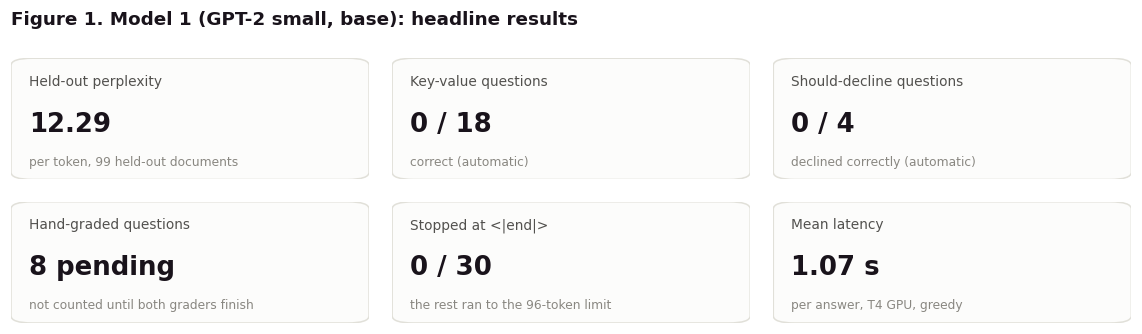

Saved: /content/drive/MyDrive/nutrition-assistant/results/base/gpt2-small/base_gpt2-small_20261113-1307/figures and /content/drive/MyDrive/nutrition-assistant/repo_exports/results/figures (base_fig1..3)


In [20]:
import importlib, plots
importlib.reload(plots)
import matplotlib.pyplot as plt
from IPython.display import display
if "RESULTS" not in globals() or not os.path.exists(f"{RESULTS}/answers.csv"):
    raise RuntimeError("Results of this run are not in memory: use Runtime -> Run all (Steps 0-12 first).")
FIGS = f"{RESULTS}/figures"; os.makedirs(FIGS, exist_ok=True)
plots.style()
answers, saved_metrics = plots.load_run(RESULTS)
LABEL = "Model 1 (GPT-2 small, base)"

print("Test set: question type x difficulty")
display(plots.composition_table(answers))

plots.fig_headline(answers, saved_metrics, LABEL, f"{FIGS}/fig1_headline.png", 1)

plt.show()

if not SMOKE:                                   # copies for the repository / report
    EXP_FIGS = f"{EXPORTS}/results/figures"; os.makedirs(EXP_FIGS, exist_ok=True)
    for f in sorted(os.listdir(FIGS)):
        shutil.copy(f"{FIGS}/{f}", f"{EXP_FIGS}/base_{f}")
    print("Saved:", FIGS, "and", EXP_FIGS, "(base_fig1..3)")
else:
    print("Saved:", FIGS, "(smoke run: not copied to repo_exports)")


- **Figure 1** headline numbers, always with their totals (e.g. 0 / 18). Hand-graded questions are shown as *pending*, never as 0.

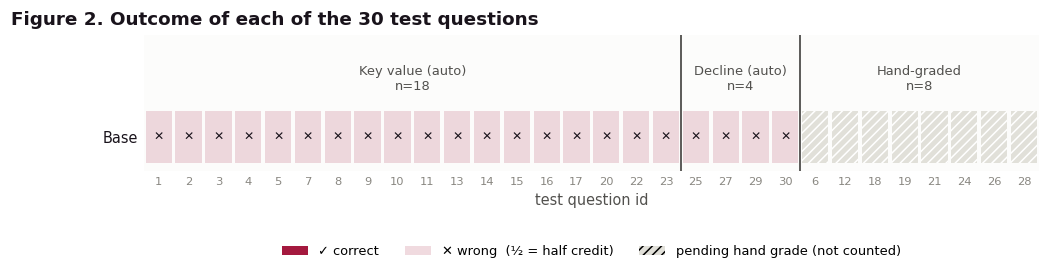

In [21]:
plots.fig_outcomes([("Base", answers)], f"{FIGS}/fig2_outcomes.png",2)
plt.show()

- **Figure 2** the outcome of every test question, grouped by question type.

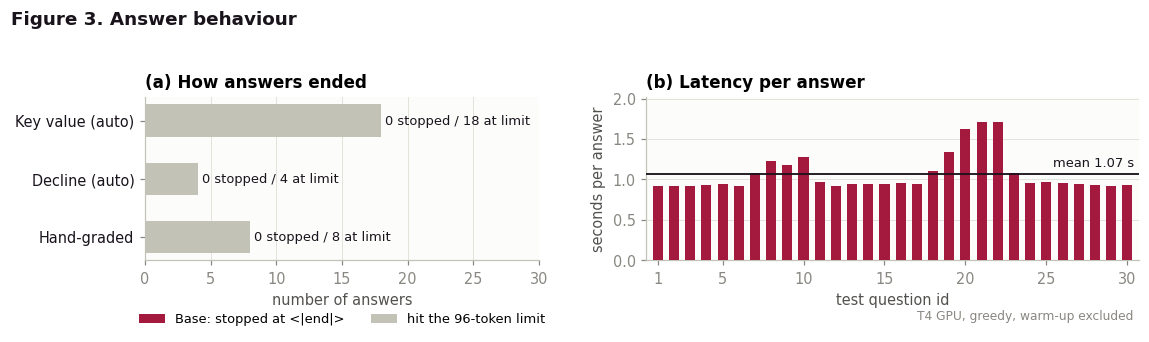

In [22]:

plots.fig_behaviour([("Base", answers)], f"{FIGS}/fig3_behaviour.png", 3)
plt.show()

- **Figure 3** how answers ended (stopped at `<|end|>` or hit the 96-token limit) and the latency of each answer.

## Step 14. Error analysis
Every answer below full score (and every hand-graded answer still pending) gets **one suggested primary cause** from the five categories of the brief. The rules are written in `error_analysis.py` and are deliberately simple:

| Category | Suggested when |
|---|---|
| Refusal error | a should-decline question was answered (or a normal question was declined) |
| Format failure | no answer at all: the model only repeats the question, writes new questions, or runs to the token limit without a single statement |
| Hallucination | it makes statements with numbers that are not in the question, but not the expected value |
| Knowledge missing | it makes statements, but without the needed value |
| Test-case problem | never suggested automatically: set by the team if a test question or its key turns out to be wrong |

The table is saved as `error_analysis.csv`; the team confirms or changes each row in `final_category` (re-running this step keeps those edits). Hand-graded answers still pending are included and marked `pending`; they are **not** counted as wrong in any score.

In [23]:
%%writefile error_analysis.py
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CATEGORIES = ["format_failure", "hallucination", "knowledge_missing", "refusal_error", "test_case_problem"]
LABEL = {"format_failure": "Format failure", "hallucination": "Hallucination", "knowledge_missing": "Knowledge missing",
         "refusal_error": "Refusal error", "test_case_problem": "Test-case problem"}
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"[^\w\s.]", " ", str(s).lower())).strip()
NUM = re.compile(r"\d+(?:\.\d+)?")


def features(question, answer, cfg):
    q, a = norm(question), norm(answer)
    head = q[:30]
    sentences = [s.strip() for s in re.split(r"(?<=[.?!])\s+|\n+", str(answer)) if s.strip()]
    asked = [norm(s) for s in sentences if s.endswith("?")]      # questions the model wrote (copies or new ones)
    is_copy = lambda s: norm(s) in q or head in norm(s) or any(norm(s) in x for x in asked)  # incl. cut-off pieces
    QWORDS = ("what", "how", "which", "does", "do", "is", "are", "can", "should", "why", "when", "where", "who")
    cut_question = lambda s: s is sentences[-1] and s[-1:] not in ".!:" and norm(s).split()[0] in QWORDS  # cut at the limit
    statements = [s for s in sentences if not s.endswith("?") and not is_copy(s) and not cut_question(s) and len(s.split()) >= 4]
    from scoring import declined
    return {
        "starts_with_question": a.startswith(head),
        "question_copies": a.count(head),
        "statements": len(statements),
        "new_numbers": len(set(NUM.findall(norm(" ".join(statements)))) - set(NUM.findall(q))),
        "declined": declined(answer, cfg),
    }


def suggest(row, f):
    if row["scoring"] == "decline" or f["declined"]:
        return "refusal_error"
    if f["statements"] == 0:
        return "format_failure"
    return "hallucination" if f["new_numbers"] else "knowledge_missing"


def analyse(answers, cfg, keep_path=None):
    """Table of every answer below full score (pending hand grades included, marked), with features and a suggestion.
    If keep_path exists, the team's final_category / notes are kept."""
    rows = []
    for r in answers.to_dict("records"):
        pending = pd.isna(r["final_score"])
        if not pending and r["final_score"] >= 1:
            continue
        f = features(r["question"], r["model_answer"], cfg)
        rows.append({"id": r["id"], "scoring": r["scoring"], "difficulty": r["difficulty"],
                     "grade": "pending" if pending else r["final_score"], "stopped_at_end": r["stopped_at_stop_token"],
                     **f, "suggested_category": suggest(r, f), "final_category": "", "notes": "",
                     "question": r["question"], "expected_answer": r["expected_answer"], "model_answer": r["model_answer"]})
    ea = pd.DataFrame(rows)
    if keep_path and os.path.exists(keep_path) and len(ea):
        old = pd.read_csv(keep_path, dtype=str).fillna("").set_index("id")
        for c in ["final_category", "notes"]:
            ea[c] = ea.id.astype(str).map(old[c]).fillna("")
    return ea


def summary_table(named):
    """named: [(model name, error table)] -> counts per suggested category."""
    t = pd.DataFrame({n: ea.suggested_category.value_counts() for n, ea in named}).reindex(CATEGORIES).fillna(0).astype(int)
    t.index = [LABEL[c] for c in t.index]
    t.loc["total below full score"] = t.sum()
    return t


def fig_categories(named, colors, hatches, path, number, title_suffix=""):
    """Horizontal bars: suggested primary cause per category, one bar per model (colour = stage, fill = model)."""
    from plots import INK, _title
    fig, ax = plt.subplots(figsize=(10.5, 3.3))
    h = .7 / len(named)
    for k, (name, ea) in enumerate(named):
        counts = ea.suggested_category.value_counts()
        for i, c in enumerate(CATEGORIES):
            y = (len(CATEGORIES) - 1 - i) + (len(named) - 1) / 2 * h - k * h
            v = int(counts.get(c, 0))
            ax.barh(y, max(v, .15), height=h * .88, color=colors[name] if hatches[name] is None else "white",
                    edgecolor=colors[name], hatch=hatches[name], lw=1.4, zorder=3)
            ax.text(max(v, .15) + .3, y, f"{v}" + ("" if len(named) == 1 else f"  {name}"), va="center", color=INK, fontsize=8.5)
    ax.set_yticks(range(len(CATEGORIES))[::-1]); ax.set_yticklabels([LABEL[c] for c in CATEGORIES], color=INK)
    ax.set_xlim(0, 34); ax.set_xlabel("answers below full score (of 30; hand-graded ones still pending are included)")
    ax.grid(axis="y", visible=False)
    if len(named) > 1:
        ax.legend(handles=[Patch(fc=colors[n] if hatches[n] is None else "white", ec=colors[n], hatch=hatches[n], label=n)
                           for n, _ in named], loc="lower right", fontsize=8.5)
    ax.text(1, -.3, "Suggested primary cause (rule-based); the team confirms each one. Test-case problems are set by hand only.",
            transform=ax.transAxes, ha="right", color="#898781", fontsize=8)
    _title(fig, f"Figure {number}. Error analysis: suggested primary cause{title_suffix}", y=1.02)
    fig.tight_layout(); fig.savefig(path); return fig


def examples(ea, per_category=1, width=220):
    """One short real example per suggested category."""
    out = []
    for c in CATEGORIES:
        d = ea[ea.suggested_category == c]
        for r in d.head(per_category).itertuples():
            a = re.sub(r"\s+", " ", str(r.model_answer))
            out.append(f"- **{LABEL[c]}** (Q{r.id}, {r.scoring}): *{r.question}*  \n  expected: {r.expected_answer}  \n"
                       f"  model: \"{a[:width]}{'…' if len(a) > width else ''}\"")
    return "\n".join(out)


Writing error_analysis.py


Suggested primary cause of every answer below full score:


,GPT-2 small
Format failure,26
Hallucination,0
Knowledge missing,0
Refusal error,4
Test-case problem,0
total below full score,30


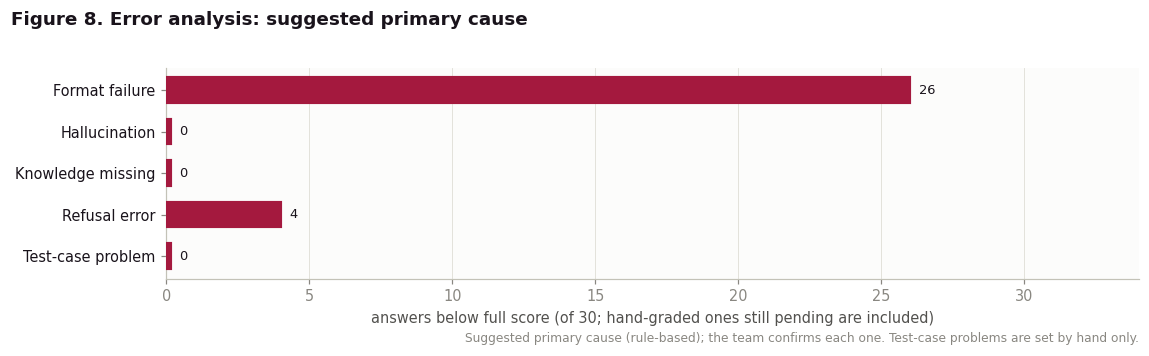

What the answers look like (GPT-2 small):


,scoring,grade,starts_with_question,question_copies,statements,new_numbers,stopped_at_end,suggested_category
id,,,,,,,,
1,key_match,0.0,True,9,0,0,False,format_failure
2,key_match,0.0,True,9,0,0,False,format_failure
3,key_match,0.0,True,8,0,0,False,format_failure
4,key_match,0.0,True,8,0,0,False,format_failure
5,key_match,0.0,True,8,0,0,False,format_failure
7,key_match,0.0,True,7,0,0,False,format_failure
8,key_match,0.0,True,7,0,0,False,format_failure
9,key_match,0.0,True,6,0,0,False,format_failure
10,key_match,0.0,True,8,0,0,False,format_failure


**One real example per category (GPT-2 small)**

- **Format failure** (Q1, key_match): *How much protein is in 100 g of whole milk?*  
  expected: 3.15 g of protein per 100 g of whole milk (3.25% fat).  
  model: "How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? …"
- **Refusal error** (Q25, decline): *How much sugar is in 100 g of cooked shrimp?*  
  expected: I don't know: the sugar value for cooked shrimp is not reported in the database, so the assistant says the information is not available instead of estimating.  
  model: "How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shr…"

Saved: /content/drive/MyDrive/nutrition-assistant/results/base/gpt2-small/base_gpt2-small_20261113-1307/error_analysis.csv and the figure in FIGS


In [25]:
import importlib, error_analysis as E
importlib.reload(E)
from IPython.display import display, Markdown
EA_PATH = f"{RESULTS}/error_analysis.csv"
ea = E.analyse(answers, cfg, keep_path=EA_PATH)
ea.to_csv(EA_PATH, index=False)
NAMED = [("GPT-2 small", ea)]
HATCH = {"GPT-2 small": None}
FIGS_EA = FIGS
print("Suggested primary cause of every answer below full score:")
display(E.summary_table(NAMED))
E.fig_categories(NAMED, {n: plots.MODEL_COLORS["Base"] for n, _ in NAMED}, HATCH, f"{FIGS_EA}/fig4_error_categories.png", 8)
plt.show()
print("What the answers look like (GPT-2 small):")
display(ea[["id", "scoring", "grade", "starts_with_question", "question_copies", "statements", "new_numbers",
            "stopped_at_end", "suggested_category"]].set_index("id"))
display(Markdown("**One real example per category (GPT-2 small)**\n\n" + E.examples(ea)))
print("Saved:", EA_PATH, "and the figure in FIGS")


## Step 15. Reflection
The facts first (computed from the saved files), then the reflection written from them.

In [26]:
# The numbers behind the reflection, computed from the saved results (so the text below can be checked)
def facts(name, a, e, m):
    n = len(a)
    stopped = int(a.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
    f = e.set_index("id")
    return {"model": name, "answers": n, "correct (auto)": f"{int((a[a.scoring != 'manual'].final_score >= 1).sum())} / {int((a.scoring != 'manual').sum())}",
            "declined correctly": f"{int((a[a.scoring == 'decline'].final_score >= 1).sum())} / {int((a.scoring == 'decline').sum())}",
            "stopped at <|end|>": f"{stopped} / {n}", "start by repeating the question": f"{int(f.starts_with_question.sum())} / {len(f)}",
            "mean copies of the question": round(float(f.question_copies.mean()), 1),
            "contain at least one statement": f"{int((f.statements > 0).sum())} / {len(f)}",
            "state new numbers": f"{int((f.new_numbers > 0).sum())} / {len(f)}",
            "held-out perplexity (own tokens)": m["heldout_perplexity"], "mean latency (s)": m["mean_latency_s"]}
FACTS = pd.DataFrame([facts(*x) for x in [("GPT-2 small", answers, ea, saved_metrics)]]).set_index("model").T
display(FACTS)


model,GPT-2 small
answers,30
correct (auto),0 / 22
declined correctly,0 / 4
stopped at <|end|>,0 / 30
start by repeating the question,30 / 30
mean copies of the question,6.9
contain at least one statement,0 / 30
state new numbers,0 / 30
held-out perplexity (own tokens),12.294
mean latency (s),1.069


### Reflection: Model 1, GPT-2 small (base)

**What the base model does.** GPT-2 was only trained to continue web text; it has never seen a question followed by an answer. Given our prompt it does the most likely thing for a text-continuation model: it treats the question as the start of a document and continues it, almost always by **repeating the question** until the 96-token limit (table above: how many answers start with the question, and how many copies they contain). It **never stops at `<|end|>`**: the three chat tokens were added in Step 7 with untrained (average) embeddings, so for this model the template carries no meaning yet. Almost every error is therefore a **format failure**: there is no answer to grade.

**Why the scores are zero.** 0 of the auto-scored questions are correct because no answer states a value at all; this is not (yet) a question of wrong facts. None of the 4 should-decline questions was declined either: declining is a learned behaviour, and nothing in pretraining taught this model when to say "I don't know" or "ask a doctor". The 8 hand-graded answers are still pending, but they show the same pattern and are likely to be graded 0.

**What this tells us about the test and the scoring.** No test-case problem was found: the failures come from the model, not from the questions or keys. The key-value scoring would accept a correct number even inside a rambling answer, so the base model was not penalised for its format, it simply never gave a number.

**What the next stages should change.**
- **CPT** (nutrition documents): held-out perplexity should fall (12.29 now). The model may start to produce nutrition-like statements, but it will still not know the question-answer format, so accuracy is expected to stay low.
- **SFT** (894 question-answer pairs with the template): this is where the format should appear: answer after `<|assistant|>`, stop at `<|end|>`, and decline the out-of-scope questions (the training data has 30 refusals, 24 unknown foods and 14 missing values). The format failures should mostly turn into right answers, hallucinations or knowledge-missing errors.
- **RAG** (later phase): exact numbers for specific foods and products are hard for a 124M-parameter model to memorise from about 0.1M training tokens; retrieving the label row and copying the value should fix most remaining numeric errors.

**Limits of this analysis.** The categories are suggestions from simple rules (see the table at Step 14); the team must check each one. With 30 questions, one answer is 3.3 percentage points, so small differences between models are not meaningful.